# Earnings Call Sentiment Analyzer

**Goal.** Measure the tone of company earnings-call transcripts with a finance-specific transformer (FinBERT), and test whether that tone relates to, and helps predict, the stock's price reaction after the call.

| Component | Choice |
|---|---|
| Transcripts | MAEC dataset (Li et al., CIKM 2020): earnings calls of S&P 1500 companies, 2015–2018, already split into sentences |
| Prices | Daily prices of S&P 500 constituents, 2013–2018 (CC0), with an equal-weighted index of all 505 stocks as the market benchmark |
| Sentiment model | **FinBERT** (`ProsusAI/finbert`; Araci, 2019), applied to every sentence (positive / negative / neutral) |
| Baseline | Loughran–McDonald (2011) finance sentiment dictionary |
| Price reaction | Event study with market-model abnormal returns, days −5 to +20 around the call |
| Evaluation | Cross-sectional regressions with firm-clustered errors, classification metrics on a later test period, and a long–short trading strategy |

**Data and model licences.** MAEC transcripts: CC BY-SA 4.0. S&P 500 price data: CC0 (Kaggle), via Plotly's MIT-licensed `datasets` repository. FinBERT model weights (`ProsusAI/finbert` on Hugging Face): CC BY-NC-SA 4.0, so non-commercial use only. Loughran–McDonald word lists: free for academic research, not for commercial use. This is a non-commercial research project. Transcripts, model weights and per-call scores are downloaded or computed at run time, cached only in the git-ignored `data/` folder, and never redistributed.

**Questions.** (1) Do calls with more positive tone see better abnormal returns? (2) Is the effect concentrated in the immediate reaction or does it drift? (3) Out of sample, does tone predict the direction of the reaction better than chance and better than a dictionary?

## 1. Setup

In [1]:
import os, subprocess, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix, roc_curve, balanced_accuracy_score

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
DATA = Path("data"); DATA.mkdir(exist_ok=True)

# FinBERT scores are computed on the first run (about 25-30 minutes on a 2-core CPU, a few minutes on a GPU)
# and cached in data/ (git-ignored). Set to True to force recomputation.
RECOMPUTE_FINBERT = False

## 2. Data

### 2.1 Transcripts (MAEC)

MAEC is published on GitHub under CC BY-SA 4.0. Each call is a folder named `YYYYMMDD_TICKER` containing `text.txt`, with one sentence per line. Only the text files are downloaded; the dataset's audio features are not needed.

In [2]:
MAEC_REPO = "https://github.com/Earnings-Call-Dataset/MAEC-A-Multimodal-Aligned-Earnings-Conference-Call-Dataset-for-Financial-Risk-Prediction.git"
MAEC_DIR = DATA / "maec"
if not (MAEC_DIR / "MAEC_Dataset").exists():
    subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--no-checkout", MAEC_REPO, str(MAEC_DIR)], check=True)
    subprocess.run(["git", "-C", str(MAEC_DIR), "sparse-checkout", "set", "--no-cone", "/MAEC_Dataset/*/text.txt"], check=True)
    subprocess.run(["git", "-C", str(MAEC_DIR), "checkout"], check=True)

calls = pd.DataFrame({"call_id": sorted(os.listdir(MAEC_DIR / "MAEC_Dataset"))})
calls["call_date"] = pd.to_datetime(calls.call_id.str[:8])
calls["ticker"] = calls.call_id.str[9:]
print(f"{len(calls):,} calls, {calls.ticker.nunique():,} companies, {calls.call_date.min().date()} to {calls.call_date.max().date()}")

3,443 calls, 1,213 companies, 2015-02-25 to 2018-06-21


### 2.2 Prices

* **Stocks:** the Kaggle *S&P 500 stock data* dataset (Nugent, 2018; licence CC0: Public Domain), with daily split-adjusted prices for the 505 S&P 500 constituents from Feb 2013 to Feb 2018. It is loaded from the unchanged copy in Plotly's public `datasets` repository (MIT licence).
* **Market:** the equal-weighted average daily return of all stocks in the same dataset. This serves as the market factor in the market model and keeps every input under a clear open licence.

A handful of one-day moves beyond ±40% in the stock data are corporate events (spin-offs such as eBay/PayPal in July 2015) or data errors, not market reactions. They are set to missing before computing returns or the market index.

In [3]:
px = pd.read_csv("https://raw.githubusercontent.com/plotly/datasets/master/all_stocks_5yr.csv", parse_dates=["date"])
close = px.pivot(index="date", columns="Name", values="close").sort_index()
R = close.pct_change()
n_extreme = int((R.abs() > 0.4).sum().sum())
R = R.mask(R.abs() > 0.4)
Rm = R.mean(axis=1)                         # equal-weighted market return
trading_days = R.index
print(f"{close.shape[1]} stocks, {len(trading_days)} trading days; {n_extreme} extreme daily returns set to missing")

505 stocks, 1259 trading days; 11 extreme daily returns set to missing


### 2.3 Event sample

A call is kept if the company is in the price data, its transcript has at least 20 usable sentences (some MAEC files are empty or truncated), and the full window is available: 250 trading days before the call (to estimate the market model) and 20 days after it. Day 0 is the first trading day on or after the call date. MAEC does not record whether a call was held before the open or after the close, so the **announcement reaction** is measured over days 0 to +1, which covers both cases.

In [4]:
EST_START, EST_END = -250, -30      # market-model estimation window (relative trading days)
EVENT_WIN = range(-5, 21)

def event_index(date):
    pos = trading_days.searchsorted(date)
    return pos if pos < len(trading_days) else None

rows = []
for c in calls.itertuples():
    if c.ticker not in R.columns:
        continue
    d0 = event_index(c.call_date)
    if d0 is None or d0 + EST_START < 1 or d0 + max(EVENT_WIN) >= len(trading_days):
        continue
    r_i, r_m = R[c.ticker].values, Rm.values
    est = slice(d0 + EST_START, d0 + EST_END + 1)
    ok = ~np.isnan(r_i[est]) & ~np.isnan(r_m[est])
    if ok.sum() < 150:
        continue
    beta, alpha = np.polyfit(r_m[est][ok], r_i[est][ok], 1)
    ar = {k: r_i[d0 + k] - (alpha + beta * r_m[d0 + k]) for k in EVENT_WIN}
    rows.append({"call_id": c.call_id, "ticker": c.ticker, "call_date": c.call_date, "day0": trading_days[d0],
                 "beta": beta, **{f"ar_{k}": v for k, v in ar.items()},
                 "car_pre": np.nansum([r_i[d0 + k] - (alpha + beta * r_m[d0 + k]) for k in range(-20, 0)])})
ev = pd.DataFrame(rows)
ev["car_0_1"] = ev[["ar_0", "ar_1"]].sum(axis=1, min_count=2)
ev["car_2_20"] = ev[[f"ar_{k}" for k in range(2, 21)]].sum(axis=1, min_count=15)
ev = ev.dropna(subset=["car_0_1"]).reset_index(drop=True)

# Some MAEC transcripts are empty or truncated. Calls with fewer than 20 sentences of 3+ words are excluded,
# because tone cannot be measured reliably from a handful of sentences.
def read_sentences(call_id):
    with open(MAEC_DIR / "MAEC_Dataset" / call_id / "text.txt", encoding="utf-8", errors="ignore") as f:
        return [s.strip() for s in f if len(s.strip().split()) >= 3]

MIN_SENTENCES = 20
ev["n_sent_raw"] = ev.call_id.map(lambda c: len(read_sentences(c)))
n_before = len(ev)
ev = ev[ev.n_sent_raw >= MIN_SENTENCES].drop(columns="n_sent_raw").reset_index(drop=True)
print(f"Excluded {n_before - len(ev)} calls with fewer than {MIN_SENTENCES} usable sentences (empty or truncated transcripts)")
print(f"Event sample: {len(ev):,} calls from {ev.ticker.nunique()} companies, {ev.call_date.min().date()} to {ev.call_date.max().date()}")
ev[["beta", "car_0_1", "car_2_20", "car_pre"]].describe().round(4)

Excluded 83 calls with fewer than 20 usable sentences (empty or truncated transcripts)
Event sample: 1,068 calls from 408 companies, 2015-02-26 to 2018-01-04


,beta,car_0_1,car_2_20,car_pre
count,1068.0000,1068.0000,1068.0000,1068.0000
mean,0.9821,0.0008,0.0016,-0.0005
std,0.3431,0.0535,0.0556,0.0611
min,0.0980,-0.2795,-0.1902,-0.3143
25%,0.7793,-0.0281,-0.0273,-0.0325
50%,0.9651,0.0035,0.0007,0.0013
75%,1.1586,0.0303,0.0289,0.0324
max,3.2091,0.2822,0.5820,0.5638


## 3. Sentiment

### 3.1 FinBERT, sentence by sentence

FinBERT is BERT further pre-trained on financial text and fine-tuned on the Financial PhraseBank (Malo et al., 2014) to label sentences as positive, negative or neutral. The weights are downloaded from Hugging Face (`ProsusAI/finbert`, licence CC BY-NC-SA 4.0). Every sentence of every call in the event sample is scored. Each call's **net tone** is the mean of P(positive) − P(negative) over its sentences, and the shares of positive and negative sentences are recorded as well.

In [5]:
def finbert_scores(call_ids, batch_size=64):
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tok = AutoTokenizer.from_pretrained("ProsusAI/finbert")
    model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").eval()
    labels = [model.config.id2label[i].lower() for i in range(3)]
    call_rows, sent_counts = [], {l: 0 for l in labels}
    ckpt = DATA / "finbert_checkpoint.pkl"
    if ckpt.exists():                      # resume an interrupted run
        call_rows, sent_counts = pd.read_pickle(ckpt)
    done = {r["call_id"] for r in call_rows}
    t0 = time.time()
    for n, cid in enumerate(call_ids):
        if cid in done:
            continue
        sents = read_sentences(cid)
        probs = []
        with torch.no_grad():
            for i in range(0, len(sents), batch_size):
                enc = tok(sents[i:i + batch_size], padding=True, truncation=True, max_length=128, return_tensors="pt")
                probs.append(torch.softmax(model(**enc).logits, dim=-1).numpy())
        P = pd.DataFrame(np.vstack(probs), columns=labels)
        top = P.idxmax(axis=1)
        for l in labels:
            sent_counts[l] += int((top == l).sum())
        call_rows.append({"call_id": cid, "n_sentences": len(sents), "fb_tone": (P.positive - P.negative).mean(),
                          "fb_pos_share": (top == "positive").mean(), "fb_neg_share": (top == "negative").mean()})
        if (n + 1) % 100 == 0:
            pd.to_pickle((call_rows, sent_counts), ckpt)
            print(f"{n + 1}/{len(call_ids)} calls scored ({time.time() - t0:.0f}s)")
    ckpt.unlink(missing_ok=True)
    return pd.DataFrame(call_rows), pd.Series(sent_counts, name="sentences")


FB_CALLS, FB_SENTS = DATA / "finbert_call_scores.csv", DATA / "finbert_sentence_label_counts.csv"
if RECOMPUTE_FINBERT or not FB_CALLS.exists():
    fb, sent_counts = finbert_scores(ev.call_id.tolist())
    fb.to_csv(FB_CALLS, index=False); sent_counts.to_csv(FB_SENTS)
else:
    fb, sent_counts = pd.read_csv(FB_CALLS), pd.read_csv(FB_SENTS, index_col=0).iloc[:, 0]
    print("Loaded FinBERT scores cached by an earlier run:", len(fb), "calls")
assert set(fb.call_id) == set(ev.call_id), "cached scores do not match the event sample"

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 27272.75it/s]

100/1068 calls scored (345s)


200/1068 calls scored (741s)


300/1068 calls scored (1095s)


... (3 outputs left out)

700/1068 calls scored (2829s)


800/1068 calls scored (3297s)


900/1068 calls scored (4058s)


1000/1068 calls scored (4777s)


### 3.2 Loughran–McDonald dictionary (baseline)

The Loughran–McDonald lists of positive and negative words were built for financial documents, where general-purpose lexicons mislabel words such as "liability" or "tax". Tone is (positive − negative) / (positive + negative) word counts over the whole transcript.

In [6]:
import pysentiment2 as ps
lm = ps.LM()
def lm_tone(call_id):
    s = lm.get_score(lm.tokenize(" ".join(read_sentences(call_id))))
    return pd.Series({"lm_tone": s["Polarity"], "lm_pos": s["Positive"], "lm_neg": s["Negative"]})
lmdf = pd.concat([ev[["call_id"]], ev.call_id.apply(lm_tone)], axis=1)

df = ev.merge(fb, on="call_id").merge(lmdf, on="call_id")
df["fb_tercile"] = pd.qcut(df.fb_tone, 3, labels=["negative", "neutral", "positive"])
print("Correlation between FinBERT and Loughran–McDonald tone:", round(df.fb_tone.corr(df.lm_tone), 3))
df[["n_sentences", "fb_tone", "fb_pos_share", "fb_neg_share", "lm_tone"]].describe().round(3)

Correlation between FinBERT and Loughran–McDonald tone: 0.544


,n_sentences,fb_tone,fb_pos_share,fb_neg_share,lm_tone
count,1068.000,1068.000,1068.000,1068.000,1068.000
mean,108.643,0.235,0.312,0.077,0.249
std,65.999,0.114,0.122,0.060,0.293
min,20.000,-0.343,0.034,0.000,-1.000
25%,59.000,0.161,0.224,0.035,0.075
50%,95.000,0.234,0.300,0.065,0.267
75%,144.000,0.311,0.394,0.105,0.455
max,436.000,0.630,0.746,0.471,1.000


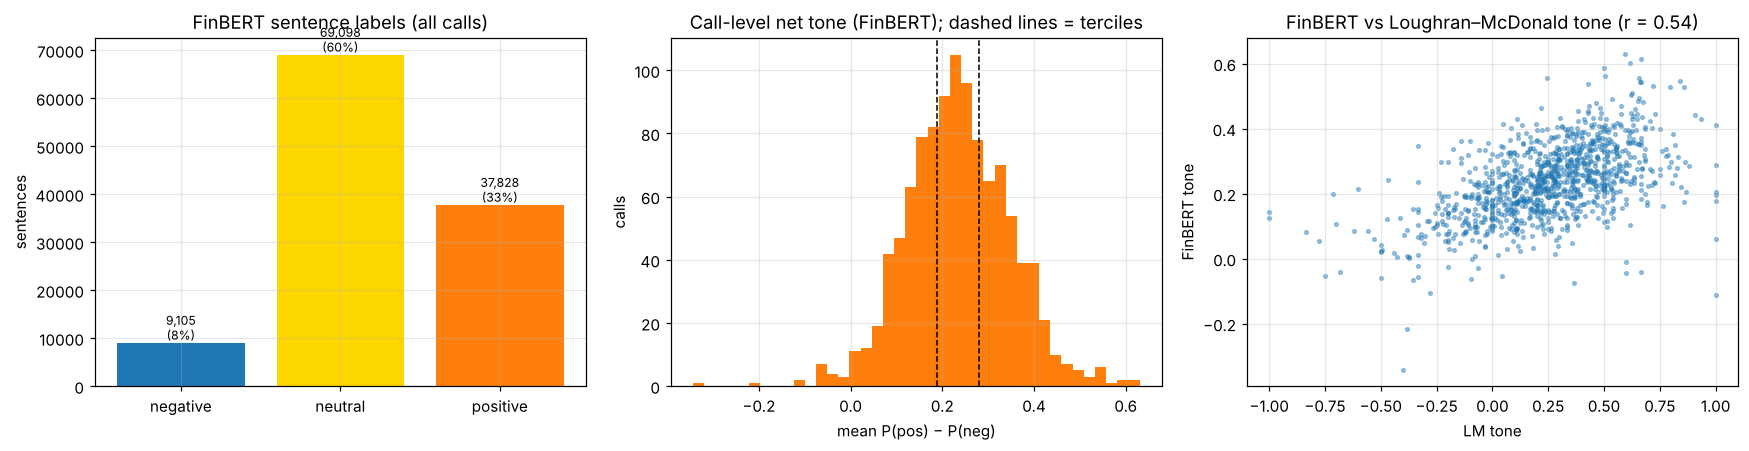

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
order = ["negative", "neutral", "positive"]
axes[0].bar(order, sent_counts[order].values, color=["tab:blue", "gold", "tab:orange"])
axes[0].set(title="FinBERT sentence labels (all calls)", ylabel="sentences")
for i, v in enumerate(sent_counts[order].values):
    axes[0].text(i, v, f"{v:,}\n({v / sent_counts.sum():.0%})", ha="center", va="bottom", fontsize=8)
axes[1].hist(df.fb_tone, bins=40, color="tab:orange")
for q in df.fb_tone.quantile([1 / 3, 2 / 3]):
    axes[1].axvline(q, c="k", ls="--", lw=1)
axes[1].set(title="Call-level net tone (FinBERT); dashed lines = terciles", xlabel="mean P(pos) − P(neg)", ylabel="calls")
axes[2].scatter(df.lm_tone, df.fb_tone, s=6, alpha=0.4)
axes[2].set(title=f"FinBERT vs Loughran–McDonald tone (r = {df.fb_tone.corr(df.lm_tone):.2f})", xlabel="LM tone", ylabel="FinBERT tone")
plt.tight_layout(); plt.show()

## 4. Event study: price reaction by tone

Calls are grouped into terciles of FinBERT net tone. Groups are relative: "negative" means the most negative third of calls in this sample. The chart shows mean cumulative abnormal returns from day −5 to +20 with 95% confidence bands.

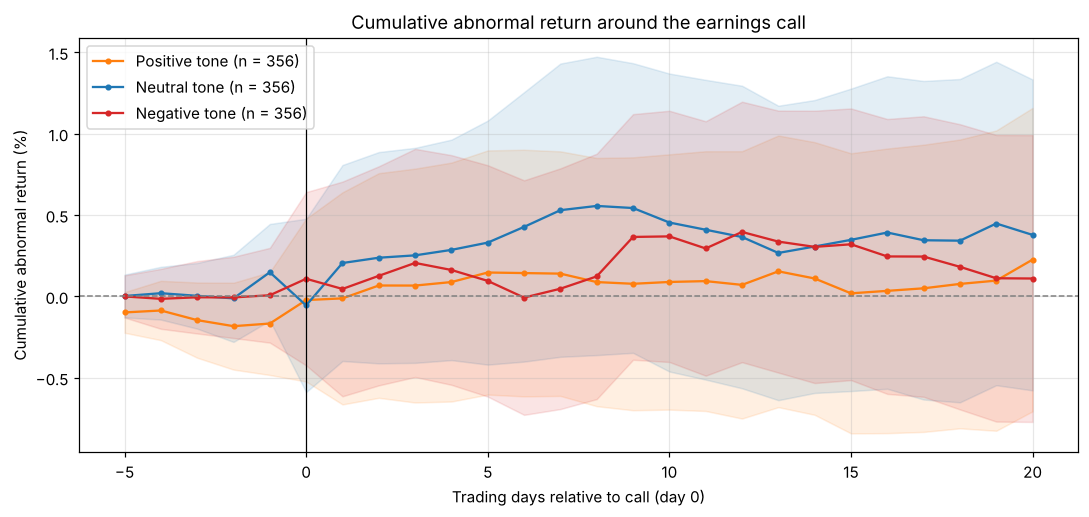

In [8]:
ar_cols = [f"ar_{k}" for k in EVENT_WIN]
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = {"positive": "tab:orange", "neutral": "tab:blue", "negative": "tab:red"}
car_paths = {}
for g in ["positive", "neutral", "negative"]:
    sub = df[df.fb_tercile == g][ar_cols].fillna(0).cumsum(axis=1) * 100
    m, se = sub.mean(), sub.std() / np.sqrt(len(sub))
    car_paths[g] = m
    ax.plot(list(EVENT_WIN), m.values, marker="o", ms=3, c=colors[g], label=f"{g.capitalize()} tone (n = {len(sub)})")
    ax.fill_between(list(EVENT_WIN), (m - 1.96 * se).values, (m + 1.96 * se).values, color=colors[g], alpha=0.12)
ax.axhline(0, c="gray", ls="--", lw=1); ax.axvline(0, c="k", lw=0.8)
ax.set(title="Cumulative abnormal return around the earnings call", xlabel="Trading days relative to call (day 0)", ylabel="Cumulative abnormal return (%)")
ax.legend(); plt.tight_layout(); plt.show()

In [9]:
def mean_ci(x):
    x = x.dropna(); m, se = x.mean(), x.std() / np.sqrt(len(x))
    return f"{m * 100:+.2f}% [{(m - 1.96 * se) * 100:+.2f}, {(m + 1.96 * se) * 100:+.2f}]"

tab = df.groupby("fb_tercile", observed=True).agg(calls=("call_id", "count"), mean_tone=("fb_tone", "mean"))
tab["CAR(0,+1), 95% CI"] = df.groupby("fb_tercile", observed=True).car_0_1.apply(mean_ci)
tab["CAR(+2,+20), 95% CI"] = df.groupby("fb_tercile", observed=True).car_2_20.apply(mean_ci)
top, bot = df[df.fb_tercile == "positive"], df[df.fb_tercile == "negative"]
for col, lab in [("car_0_1", "CAR(0,+1)"), ("car_2_20", "CAR(+2,+20)")]:
    t, p = stats.ttest_ind(top[col].dropna(), bot[col].dropna(), equal_var=False)
    print(f"{lab}: positive − negative tercile = {(top[col].mean() - bot[col].mean()) * 100:+.2f} pp  (Welch t = {t:.2f}, p = {p:.4f})")
tab.round(4)

CAR(0,+1): positive − negative tercile = +0.12 pp  (Welch t = 0.29, p = 0.7753)
CAR(+2,+20): positive − negative tercile = +0.17 pp  (Welch t = 0.43, p = 0.6699)


,calls,mean_tone,"CAR(0,+1), 95% CI","CAR(+2,+20), 95% CI"
fb_tercile,,,,
negative,356,0.1146,"+0.04% [-0.54, +0.62]","+0.06% [-0.50, +0.62]"
neutral,356,0.2333,"+0.06% [-0.49, +0.60]","+0.17% [-0.43, +0.77]"
positive,356,0.3584,"+0.15% [-0.39, +0.70]","+0.24% [-0.33, +0.81]"


## 5. Cross-sectional regressions

Tercile sorts ignore magnitude and confounders. The regressions below relate each call's abnormal return to standardised tone, controlling for the stock's abnormal return over the 20 days before the call, with year fixed effects. Standard errors are clustered by company, because the same firm appears in several quarters.

In [10]:
reg = df.copy()
for c in ["fb_tone", "lm_tone"]:
    reg[c + "_z"] = (reg[c] - reg[c].mean()) / reg[c].std()
reg["year"] = reg.call_date.dt.year
reg["car_0_1_pct"], reg["car_2_20_pct"], reg["car_pre_pct"] = reg.car_0_1 * 100, reg.car_2_20 * 100, reg.car_pre * 100

def fit(formula, data):
    d = data.dropna(subset=[formula.split("~")[0].strip()])
    return smf.ols(formula, d).fit(cov_type="cluster", cov_kwds={"groups": d.ticker})

specs = {
    "(1) CAR(0,1): FinBERT": fit("car_0_1_pct ~ fb_tone_z + car_pre_pct + C(year)", reg),
    "(2) CAR(0,1): LM": fit("car_0_1_pct ~ lm_tone_z + car_pre_pct + C(year)", reg),
    "(3) CAR(0,1): both": fit("car_0_1_pct ~ fb_tone_z + lm_tone_z + car_pre_pct + C(year)", reg),
    "(4) CAR(2,20): FinBERT": fit("car_2_20_pct ~ fb_tone_z + car_pre_pct + C(year)", reg),
}
out = {}
for name, m in specs.items():
    col = {}
    for v in ["fb_tone_z", "lm_tone_z", "car_pre_pct"]:
        if v in m.params:
            col[v] = f"{m.params[v]:.3f} ({m.bse[v]:.3f}){'***' if m.pvalues[v] < 0.01 else '**' if m.pvalues[v] < 0.05 else '*' if m.pvalues[v] < 0.1 else ''}"
    col["N"], col["R²"] = int(m.nobs), f"{m.rsquared:.3f}"
    out[name] = col
print("Coefficient (firm-clustered SE); dependent variable in %, tone standardised. * p<0.1, ** p<0.05, *** p<0.01. Year fixed effects included.")
pd.DataFrame(out).fillna("")

Coefficient (firm-clustered SE); dependent variable in %, tone standardised. * p<0.1, ** p<0.05, *** p<0.01. Year fixed effects included.


,"(1) CAR(0,1): FinBERT","(2) CAR(0,1): LM","(3) CAR(0,1): both","(4) CAR(2,20): FinBERT"
fb_tone_z,0.210 (0.160),,0.377 (0.204)*,-0.052 (0.171)
car_pre_pct,0.006 (0.044),0.007 (0.043),0.006 (0.044),0.156 (0.053)***
N,1068,1068,1068,1068
R²,0.003,0.002,0.005,0.030
lm_tone_z,,-0.100 (0.161),-0.293 (0.204),


## 6. Prediction on a later period

Can tone predict whether the announcement reaction, CAR(0,+1), will be positive? Logistic regressions are trained on calls from 2015–2016 and tested on calls from 2017–2018 that the model has never seen. Three feature sets are compared with a majority-class baseline.

In [11]:
df["up"] = (df.car_0_1 > 0).astype(int)
train, test = df[df.call_date < "2017-01-01"], df[df.call_date >= "2017-01-01"]
feature_sets = {"Loughran–McDonald": ["lm_tone"],
                "FinBERT": ["fb_tone", "fb_pos_share", "fb_neg_share"],
                "FinBERT + LM": ["fb_tone", "fb_pos_share", "fb_neg_share", "lm_tone"]}
clf_rows, probs = [], {}
maj = int(train.up.mean() >= 0.5)
clf_rows.append({"model": f"Majority class ('{'up' if maj else 'down'}')", "accuracy": accuracy_score(test.up, np.full(len(test), maj)),
                 "balanced accuracy": 0.5, "ROC-AUC": 0.5, "F1 (up)": f1_score(test.up, np.full(len(test), maj), zero_division=0)})
for name, cols in feature_sets.items():
    model = make_pipeline(StandardScaler(), LogisticRegression())
    model.fit(train[cols], train.up)
    p = model.predict_proba(test[cols])[:, 1]; pred = (p >= 0.5).astype(int)
    probs[name] = p
    clf_rows.append({"model": name, "accuracy": accuracy_score(test.up, pred), "balanced accuracy": balanced_accuracy_score(test.up, pred),
                     "ROC-AUC": roc_auc_score(test.up, p), "F1 (up)": f1_score(test.up, pred)})
print(f"train: {len(train)} calls (2015–2016), test: {len(test)} calls (2017–2018); share of positive reactions in test = {test.up.mean():.1%}")
clf = pd.DataFrame(clf_rows).set_index("model")
# Bootstrap 95% CI for the FinBERT model's test ROC-AUC
rng = np.random.default_rng(0)
boot = [roc_auc_score(test.up.values[i], probs["FinBERT"][i]) for i in (rng.integers(0, len(test), len(test)) for _ in range(2000))]
print(f"FinBERT ROC-AUC bootstrap 95% CI: [{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]")
clf.round(3)

train: 671 calls (2015–2016), test: 397 calls (2017–2018); share of positive reactions in test = 51.1%


FinBERT ROC-AUC bootstrap 95% CI: [0.470, 0.590]


,accuracy,balanced accuracy,ROC-AUC,F1 (up)
model,,,,
Majority class ('up'),0.511,0.500,0.500,0.677
Loughran–McDonald,0.511,0.500,0.480,0.677
FinBERT,0.506,0.497,0.532,0.647
FinBERT + LM,0.516,0.508,0.521,0.650


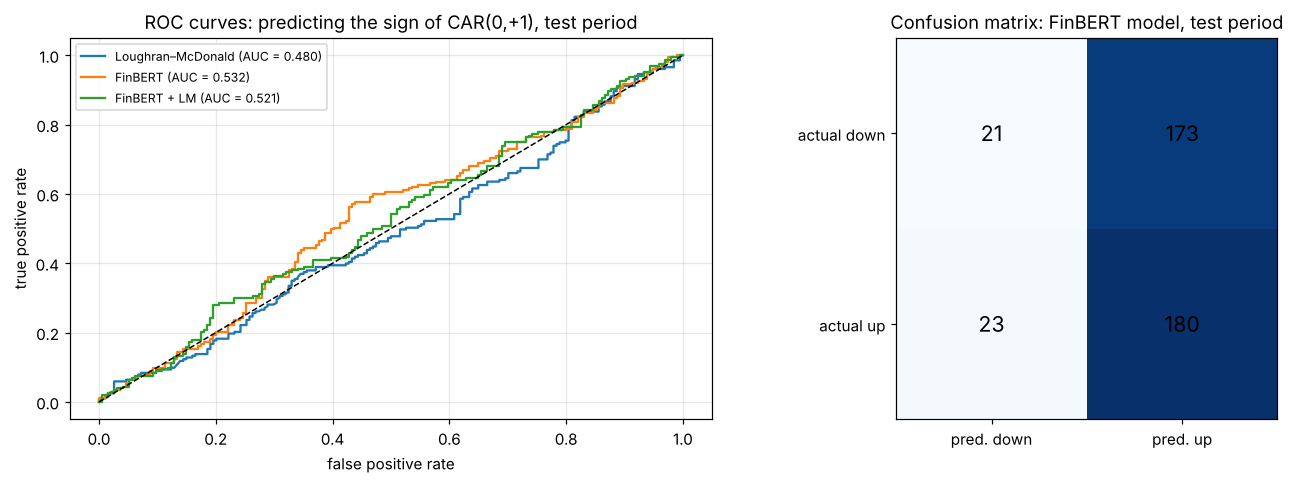

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(test.up, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(test.up, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curves: predicting the sign of CAR(0,+1), test period", xlabel="false positive rate", ylabel="true positive rate"); axes[0].legend(fontsize=8)
cm = confusion_matrix(test.up, (probs["FinBERT"] >= 0.5).astype(int))
axes[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
axes[1].set_xticks([0, 1], ["pred. down", "pred. up"]); axes[1].set_yticks([0, 1], ["actual down", "actual up"])
axes[1].set_title("Confusion matrix: FinBERT model, test period"); axes[1].grid(False)
plt.tight_layout(); plt.show()

## 7. Trading strategy (test period)

The announcement reaction cannot be traded on the call's text, because the text becomes available only as the reaction happens. The strategy therefore tests the **post-call drift**. After the close on day +1 it goes long the calls in the most positive FinBERT tercile and short those in the most negative, with tercile cut-offs taken from the **training** period. Each position is held through day +20. Returns are market-adjusted (abnormal), and a 10 bp round-trip cost per side is deducted.

In [13]:
cuts = train.fb_tone.quantile([1 / 3, 2 / 3]).values
t = test.copy()
t["signal"] = np.where(t.fb_tone >= cuts[1], 1, np.where(t.fb_tone <= cuts[0], -1, 0))
COST_RT = 0.002   # 10 bp in + 10 bp out
t["trade_ret"] = t.signal * t.car_2_20 - COST_RT * (t.signal != 0)
trades = t[t.signal != 0].dropna(subset=["car_2_20"])
longs, shorts = trades[trades.signal == 1], trades[trades.signal == -1]
summary = pd.DataFrame({
    "trades": [len(longs), len(shorts), len(trades)],
    "mean abnormal return per trade": [longs.trade_ret.mean(), shorts.trade_ret.mean(), trades.trade_ret.mean()],
    "hit rate": [(longs.trade_ret > 0).mean(), (shorts.trade_ret > 0).mean(), (trades.trade_ret > 0).mean()],
    "t-stat": [stats.ttest_1samp(x.trade_ret, 0).statistic for x in (longs, shorts, trades)],
}, index=["long (positive tone)", "short (negative tone)", "all trades"])
summary.style.format({"mean abnormal return per trade": "{:+.2%}", "hit rate": "{:.1%}", "t-stat": "{:.2f}"})

,trades,mean abnormal return per trade,hit rate,t-stat
long (positive tone),255,+0.16%,53.7%,0.51
short (negative tone),62,-0.67%,41.9%,-0.95
all trades,317,+0.00%,51.4%,0.00


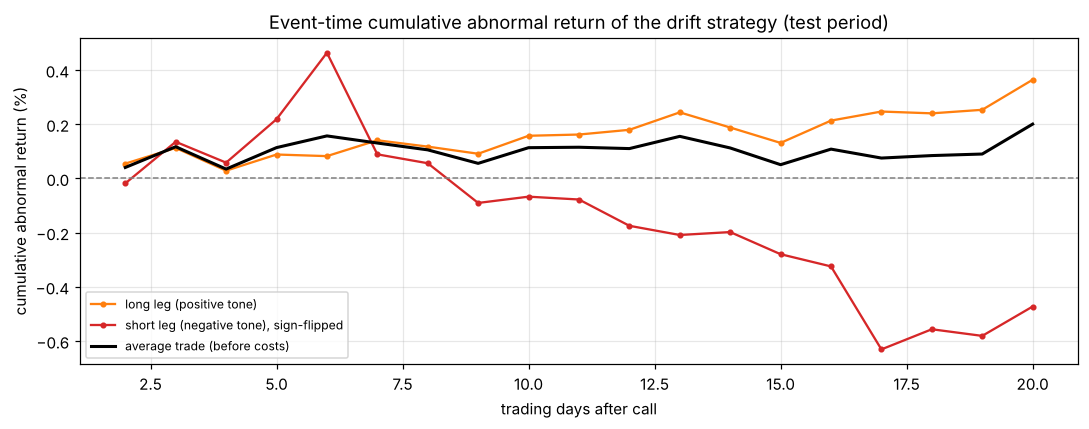

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
drift_cols = [f"ar_{k}" for k in range(2, 21)]
for sig, lab, c in [(1, "long leg (positive tone)", "tab:orange"), (-1, "short leg (negative tone), sign-flipped", "tab:red")]:
    path = (sig * t[t.signal == sig][drift_cols].fillna(0)).cumsum(axis=1).mean() * 100
    ax.plot(range(2, 21), path.values, marker="o", ms=3, c=c, label=lab)
ls = (t[t.signal != 0][drift_cols].fillna(0).mul(t[t.signal != 0].signal, axis=0)).cumsum(axis=1).mean() * 100
ax.plot(range(2, 21), ls.values, c="k", lw=2, label="average trade (before costs)")
ax.axhline(0, c="gray", ls="--", lw=1)
ax.set(title="Event-time cumulative abnormal return of the drift strategy (test period)", xlabel="trading days after call", ylabel="cumulative abnormal return (%)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 8. Results and discussion

The headline numbers from this run are collected below; the interpretation follows.

In [15]:
m1 = specs["(1) CAR(0,1): FinBERT"]; m4 = specs["(4) CAR(2,20): FinBERT"]
print(f"Sample: {len(df):,} calls, {df.ticker.nunique()} companies, {df.call_date.min():%b %Y} – {df.call_date.max():%b %Y}")
print(f"Positive − negative tercile, CAR(0,+1): {(top.car_0_1.mean() - bot.car_0_1.mean()) * 100:+.2f} pp")
print(f"Regression: +1 sd FinBERT tone → CAR(0,+1) {m1.params['fb_tone_z']:+.2f} pp (clustered p = {m1.pvalues['fb_tone_z']:.4f}); "
      f"CAR(+2,+20) {m4.params['fb_tone_z']:+.2f} pp (p = {m4.pvalues['fb_tone_z']:.4f})")
print(f"Out-of-sample ROC-AUC (sign of CAR(0,+1)): FinBERT {clf.loc['FinBERT', 'ROC-AUC']:.3f}, LM {clf.loc['Loughran–McDonald', 'ROC-AUC']:.3f}")
print(f"Drift strategy, mean net abnormal return per trade: {trades.trade_ret.mean():+.2%} (t = {stats.ttest_1samp(trades.trade_ret, 0).statistic:.2f}, n = {len(trades)})")

Sample: 1,068 calls, 408 companies, Feb 2015 – Jan 2018
Positive − negative tercile, CAR(0,+1): +0.12 pp
Regression: +1 sd FinBERT tone → CAR(0,+1) +0.21 pp (clustered p = 0.1891); CAR(+2,+20) -0.05 pp (p = 0.7623)
Out-of-sample ROC-AUC (sign of CAR(0,+1)): FinBERT 0.532, LM 0.480
Drift strategy, mean net abnormal return per trade: +0.00% (t = 0.00, n = 317)


**How to read the results**

* The **event-study chart and tercile table** show whether calls with more positive tone are followed by higher abnormal returns, and whether the gap opens at the announcement (days 0 to +1) or keeps widening afterwards.
* The **regressions** test the same relationship using the full range of tone values, with controls and firm-clustered standard errors. Comparing columns (1)–(3) shows whether FinBERT carries information beyond the dictionary measure.
* The **out-of-sample classification** is the strictest test. With only text features, a single quarterly signal and a noisy target, a modest ROC-AUC above 0.5 is a realistic result; the bootstrap interval shows how certain it is.
* The **trading strategy** asks whether any drift can be harvested after costs. A mean per-trade return near zero, or a t-statistic below about 2, means tone is not a standalone trading signal in this sample, which is consistent with efficient pricing of public information.

**Limitations.**
* The sample is restricted to companies in the S&P 500 price data, about a third of MAEC calls.
* Earnings surprises are not available. Part of the tone effect may reflect the earnings news itself rather than how management talks about it, and controlling for analyst-forecast surprises is the natural next step.
* Call timing (before the open or after the close) is unknown, so day-level timing is approximate.
* Prices exclude dividends. This matters little over a 20-day window. The market factor is an equal-weighted index rather than the value-weighted S&P 500.
* FinBERT was fine-tuned on news sentences, not call transcripts, and question-and-answer exchanges with analysts may need different treatment from prepared remarks.

In [16]:
print({"numpy": np.__version__, "pandas": pd.__version__, "statsmodels": __import__("statsmodels").__version__,
       "scikit-learn": __import__("sklearn").__version__})

{'numpy': '2.5.3', 'pandas': '3.0.5', 'statsmodels': '0.15.0', 'scikit-learn': '1.9.1'}
